# 02A · Explore the data, then try simple maths (OLS) and show why it fails

**Why this notebook exists:** before using an advanced model, a good analyst tries the simplest
one. Ordinary least squares (OLS) regression asks: "for every extra ₹1 on a channel, how much
more revenue do we see?" If it worked, we would not need anything fancier. It does not, and
this notebook shows exactly why (AI1 baseline).

Data: sealed stage-1 release, national weekly totals, weeks 1–87.

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels")


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from common import load, national, CHANNELS, LABEL, COLOR, INK, INK2, style, save

style()
w, p = load()
nat = national(w)
spend_cols = [f"spend_{c}_lakh" for c in CHANNELS]

## 1. What moves together?
If two channels' budgets rise and fall together, no model can easily tell which one caused sales.

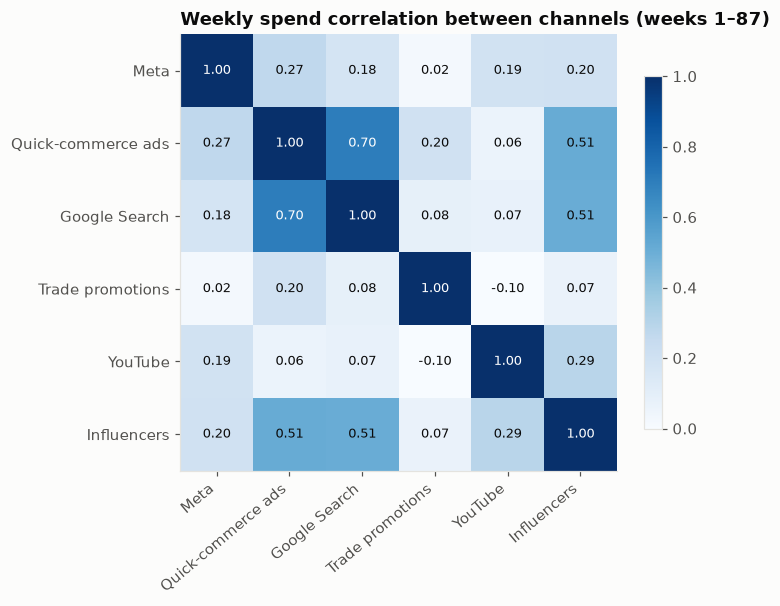

Meta vs YouTube spend correlation in weeks 20–49: 0.90


In [2]:
X = nat[spend_cols].rename(columns=lambda c: LABEL[c.replace("spend_", "").replace("_lakh", "")])
corr = X.corr()
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if corr.values[i, j] > 0.6 else INK)
ax.grid(False)
ax.set_title("Weekly spend correlation between channels (weeks 1–87)")
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "02A_spend_correlation"); plt.show()

win = nat.loc[20:49, ["spend_meta_lakh", "spend_youtube_lakh"]].corr().iloc[0, 1]
print(f"Meta vs YouTube spend correlation in weeks 20–49: {win:.2f}")

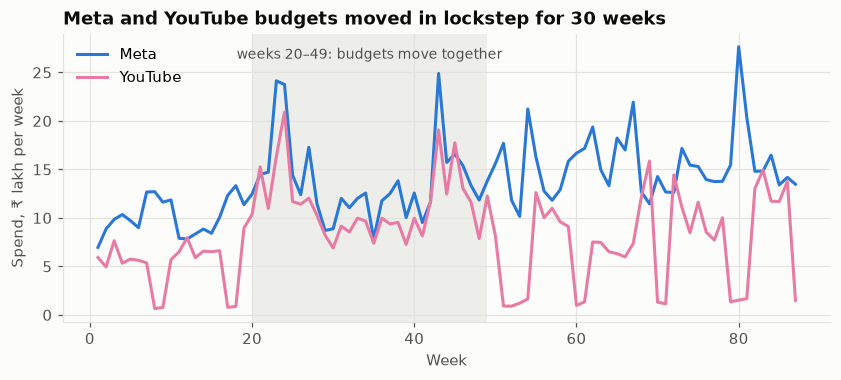

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for c in ["meta", "youtube"]:
    ax.plot(nat.index, nat[f"spend_{c}_lakh"], color=COLOR[c], label=LABEL[c])
ax.axvspan(20, 49, color="#e4e3df", alpha=0.6, lw=0)
ax.text(34.5, ax.get_ylim()[1] * 0.95, "weeks 20–49: budgets move together", ha="center", va="top", fontsize=9, color=INK2)
ax.set_xlabel("Week"); ax.set_ylabel("Spend, ₹ lakh per week")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Meta and YouTube budgets moved in lockstep for 30 weeks")
save(fig, "02A_meta_youtube_lockstep"); plt.show()

**Variance inflation factor (VIF):** how much a channel's spend can be predicted from the others.
Above 5 is a warning, above 10 is serious.

In [4]:
controls = ["price_index", "promo_flag", "festive_flag", "temp_c", "competitor_index", "dark_store_count"]
design = nat[spend_cols + controls].copy()
design["t"] = np.arange(len(design))            # growth trend
Xc = sm.add_constant(design)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=design.columns)
vif.index = [LABEL.get(i.replace("spend_", "").replace("_lakh", ""), i) for i in vif.index]
vif.round(1).sort_values(ascending=False).to_frame("VIF")

,VIF
dark_store_count,115.7
t,113.5
promo_flag,16.4
Trade promotions,15.4
Google Search,6.4
price_index,5.6
temp_c,5.5
Quick-commerce ads,3.6
Influencers,1.8
festive_flag,1.6


## 2. The simple model (OLS)
Revenue = constant + trend + controls + (coefficient × spend) for each channel.
Each spend coefficient is read as "revenue per ₹1 of spend", the model's ROI.
We fit on weeks 1–79 and keep weeks 80–87 aside to test predictions.

In [5]:
y = nat["revenue_lakh"]
train, test = nat.index <= 79, nat.index > 79
ols = sm.OLS(y[train], Xc[train]).fit()
coef = ols.params[spend_cols]
ci = ols.conf_int(alpha=0.10).loc[spend_cols]
res = pd.DataFrame({"OLS ROI (₹ per ₹1)": coef, "90% low": ci[0], "90% high": ci[1], "p-value": ols.pvalues[spend_cols]})
res.index = [LABEL[c.replace("spend_", "").replace("_lakh", "")] for c in res.index]
pred = ols.predict(Xc[test])
mape = (np.abs(pred - y[test]) / y[test]).mean()
print(f"R² (training): {ols.rsquared:.3f}   |   holdout MAPE weeks 80–87: {mape:.1%}")
res.round(2)

R² (training): 0.967   |   holdout MAPE weeks 80–87: 4.6%


,OLS ROI (₹ per ₹1),90% low,90% high,p-value
Meta,0.18,-0.24,0.59,0.48
Quick-commerce ads,0.35,-0.32,1.03,0.39
Google Search,3.00,1.87,4.12,0.00
Trade promotions,0.93,-0.01,1.87,0.10
YouTube,0.59,0.25,0.94,0.01
Influencers,-0.33,-1.05,0.39,0.45


## 3. Three failures
**Failure 1: unstable coefficients.** Fit the same model on two overlapping windows. If the
answers change a lot, the model cannot be trusted with a budget.

                    weeks 1–60  weeks 28–87  sign flips?
Meta                      0.28        -0.32         True
Quick-commerce ads        0.08         0.72        False
Google Search             2.58         2.38        False
Trade promotions          1.66        -0.45         True
YouTube                   0.51         0.51        False
Influencers               0.07        -0.30         True


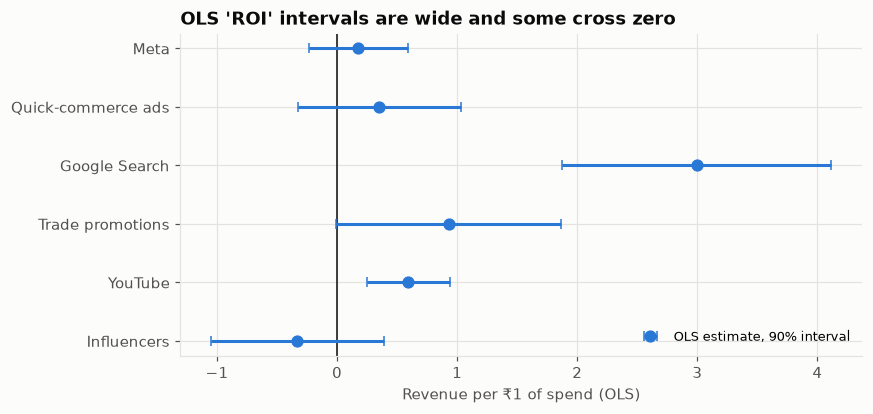

In [6]:
def fit(mask):
    return sm.OLS(y[mask], Xc[mask]).fit().params[spend_cols]
early, late = fit(nat.index <= 60), fit(nat.index >= 28)
stab = pd.DataFrame({"weeks 1–60": early, "weeks 28–87": late})
stab["sign flips?"] = np.sign(stab.iloc[:, 0]) != np.sign(stab.iloc[:, 1])
stab.index = res.index
print(stab.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(res))
ax.axvline(0, color=INK, lw=1)
ax.errorbar(res["OLS ROI (₹ per ₹1)"], yy, xerr=[res["OLS ROI (₹ per ₹1)"] - res["90% low"], res["90% high"] - res["OLS ROI (₹ per ₹1)"]],
            fmt="o", color="#2a78d6", ms=7, capsize=3, lw=2, label="OLS estimate, 90% interval")
ax.set_yticks(yy, res.index); ax.invert_yaxis()
ax.set_xlabel("Revenue per ₹1 of spend (OLS)")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("OLS 'ROI' intervals are wide and some cross zero")
save(fig, "02A_ols_intervals"); plt.show()

**Failure 2: autocorrelation.** Ads keep working for weeks after they run (carry-over), but OLS
assumes each week is independent. The Durbin–Watson statistic is 2 when errors are independent;
well below 2 means this week's error predicts next week's.

**Failure 3: uneven error spread (heteroskedasticity).** The Breusch–Pagan test checks whether
errors grow as revenue grows. A p-value below 0.05 means they do, so the intervals above are wrong.

In [7]:
dw = durbin_watson(ols.resid)
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Durbin–Watson: {dw:.2f}  (2 = independent errors)")
print(f"Breusch–Pagan p-value: {bp_p:.3f}")

# geo-level panel (more data, same problem) for the heteroskedasticity check
wg = w[w.week <= 79].copy()
Xg = pd.get_dummies(wg[spend_cols + controls + ["geo"]], columns=["geo"], drop_first=True, dtype=float)
Xg["t"] = wg["week"]
olsg = sm.OLS(wg["revenue_lakh"], sm.add_constant(Xg)).fit()
print(f"City-level panel: Durbin–Watson {durbin_watson(olsg.resid):.2f}, "
      f"Breusch–Pagan p-value {het_breuschpagan(olsg.resid, olsg.model.exog)[1]:.2e}")

Durbin–Watson: 0.63  (2 = independent errors)
Breusch–Pagan p-value: 0.091
City-level panel: Durbin–Watson 0.97, Breusch–Pagan p-value 2.15e-17


## 4. Compare with what the platforms say

In [8]:
plat = p.groupby("channel").apply(lambda d: d.reported_revenue_lakh.sum() / d.spend_lakh.sum(), include_groups=False)
cmp_ = pd.DataFrame({"Platform-claimed ROAS": plat.reindex(CHANNELS).values,
                     "OLS ROI": res["OLS ROI (₹ per ₹1)"].values}, index=res.index)
cmp_.round(2)

,Platform-claimed ROAS,OLS ROI
Meta,7.46,0.18
Quick-commerce ads,7.27,0.35
Google Search,4.93,3.00
Trade promotions,2.64,0.93
YouTube,2.52,0.59
Influencers,4.78,-0.33


## 5. So what (for the CFO)

In [9]:
neg = res.index[res["OLS ROI (₹ per ₹1)"] < 0].tolist()
cross = res.index[(res["90% low"] < 0) & (res["90% high"] > 0)].tolist()
flips = stab.index[stab["sign flips?"]].tolist()
print("SO WHAT")
print(f"1. Decision: do not budget from OLS either. {len(cross)} of 6 channel intervals include zero"
      + (f"; {', '.join(neg)} even come out negative" if neg else "")
      + (f"; {', '.join(flips)} flip sign between time windows." if flips else "."))
top = res["OLS ROI (₹ per ₹1)"].idxmax()
print(f"2. Trap: OLS forecasts well (holdout MAPE {mape:.1%}) yet its channel answers are wrong. It rates {top} highest "
      f"(₹{res.loc[top, 'OLS ROI (₹ per ₹1)']:.2f} per ₹1) because that spend rises when demand is already high: good fit ≠ right causes.")
print(f"3. Why it fails: budgets move together (Meta–YouTube r = {win:.2f} in weeks 20–49), ads carry over "
      f"(Durbin–Watson {dw:.2f}), and errors are uneven across cities (Breusch–Pagan p < 0.001). "
      "Next: a Bayesian MMM with carry-over, saturation and honest intervals (notebook 02B).")

SO WHAT
1. Decision: do not budget from OLS either. 4 of 6 channel intervals include zero; Influencers even come out negative; Meta, Trade promotions, Influencers flip sign between time windows.
2. Trap: OLS forecasts well (holdout MAPE 4.6%) yet its channel answers are wrong. It rates Google Search highest (₹3.00 per ₹1) because that spend rises when demand is already high: good fit ≠ right causes.
3. Why it fails: budgets move together (Meta–YouTube r = 0.90 in weeks 20–49), ads carry over (Durbin–Watson 0.63), and errors are uneven across cities (Breusch–Pagan p < 0.001). Next: a Bayesian MMM with carry-over, saturation and honest intervals (notebook 02B).
